In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import geopandas as gpd
import contextily as ctx
import scipy.stats

In [42]:
pypsa_data_dir = "../Data/eq_handoff_fullcats"
expansion_scenario = 'bau'
agg_type = "disagg"
asset_fp = os.path.join(pypsa_data_dir, expansion_scenario, agg_type, "assets_all.csv")
asset_df = pd.read_csv(asset_fp)
asset_df['asset_id'] = range(len(asset_df))
asset_gdf = gpd.GeoDataFrame(asset_df, geometry=gpd.points_from_xy(asset_df.lon, asset_df.lat))

(3759, 73)


/tmp/ipykernel_1683583/1213201235.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  damage_samples['Mode'] = scipy.stats.mode(damage_samples.iloc[:,1:].values, axis=1)[0]


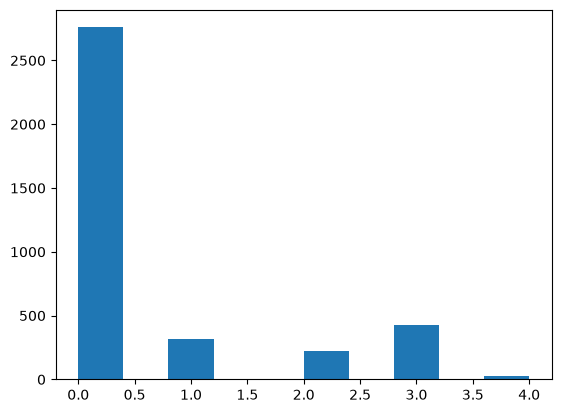

In [43]:
eq_scenario_dir = "/resnick/groups/enceladus/jyzhao/CAPowerResilience/Data/BSSC2014_scenarios/Mw7.8_SSanAndreas_SM_NSB_SSB_BG_CO"
expansion_scenario = 'bau'
asset_info_pelicun_fp = os.path.join(eq_scenario_dir,expansion_scenario, "asset_info_pelicun.csv")
asset_info_pelicun_df = pd.read_csv(asset_info_pelicun_fp)
print(asset_info_pelicun_df.shape)

damage_samples = pd.read_csv(os.path.join(eq_scenario_dir, expansion_scenario, "damage.csv"))
damage_samples['Mode'] = scipy.stats.mode(damage_samples.iloc[:,1:].values, axis=1)[0]
plt.hist(damage_samples['Mode']);

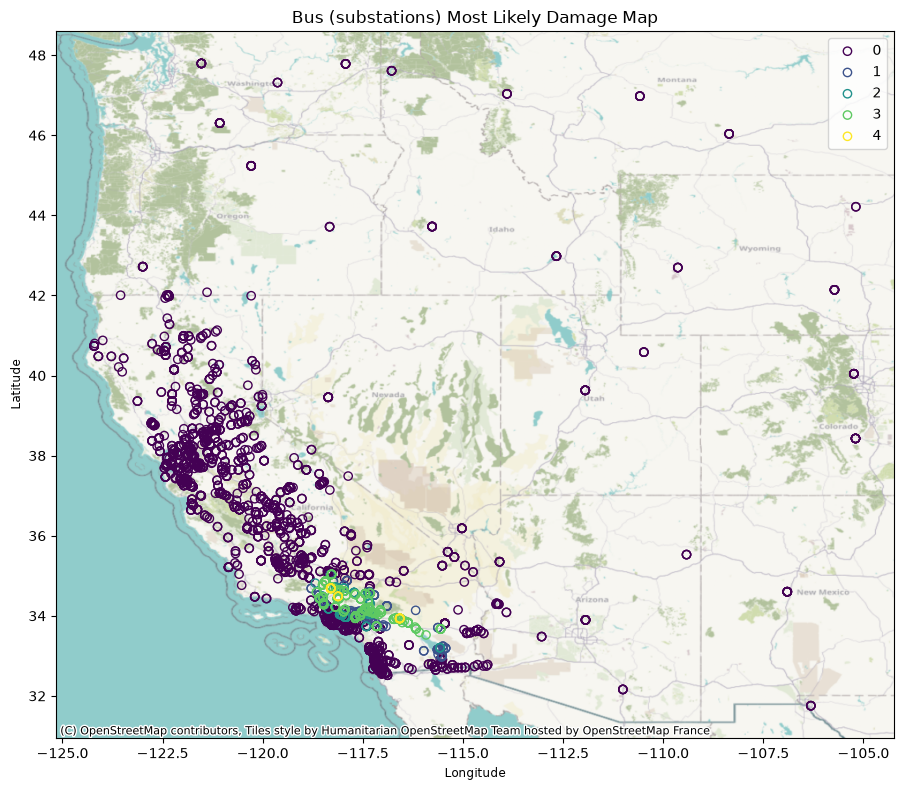

In [52]:
bus_damage_gdf = pd.merge(
    asset_gdf,
    damage_samples[['id', 'Mode']],
    left_on='asset_id',
    right_on='id',
    how='left'
)
bus_damage_gdf['Mode'] = bus_damage_gdf['Mode'].astype(str)
fig, ax = plt.subplots(figsize=(10, 8))
bus_damage_gdf.plot(ax=ax,
    marker='o', facecolor='none', column = 'Mode',
    cmap='viridis',
     legend=True,
    )
ctx.add_basemap(ax, crs='EPSG:4326')
ax.set_title("Bus (substations) Most Likely Damage Map")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.tight_layout()

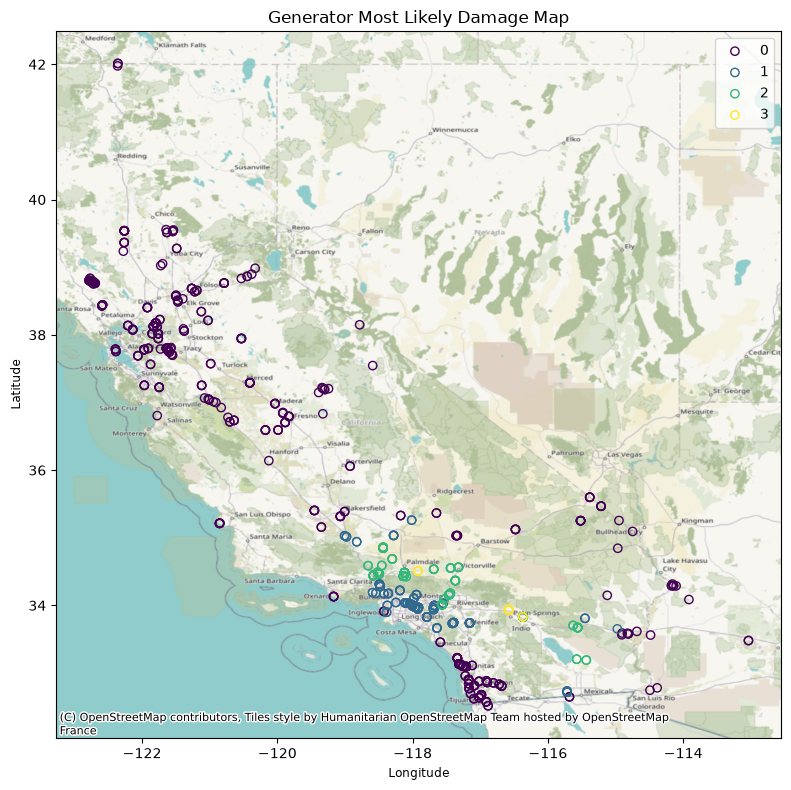

In [58]:
generator_gdf = asset_gdf[asset_gdf['asset_type'] == 'generator']
damage_samples['gen_id'] = damage_samples['id'] - len(asset_df)
generator_damage_gdf = pd.merge(
    generator_gdf,
    damage_samples[['gen_id', 'Mode']],
    left_on='asset_id',
    right_on='gen_id',
    how='left'
)
generator_damage_gdf = generator_damage_gdf.dropna(subset=['Mode'])
generator_damage_gdf['Mode'] = generator_damage_gdf['Mode'].astype(int).astype(str)
fig, ax = plt.subplots(figsize=(10, 8))
generator_damage_gdf.plot(ax=ax,
    marker='o', facecolor='none', column = 'Mode',
    cmap='viridis',
     legend=True,
    )
ctx.add_basemap(ax, crs='EPSG:4326')
ax.set_title("Generator Most Likely Damage Map")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.tight_layout()